In [129]:
print("radha")

radha


In [130]:
from typing import Literal,TypedDict
from typing_extensions import Annotated
import operator

class TweetState(TypedDict):
    topic:str
    tweet:str
    evaluation:Literal["approved","need_improvement"]
    feedback:str
    iteration:int
    max_iteration:int

    tweet_history:Annotated[list[str],operator.add]
    feedback_history:Annotated[list[int],operator.add]

In [131]:
import os
from dotenv import load_dotenv
from langchain_groq import ChatGroq
from langgraph.graph import StateGraph,START,END
from typing import TypedDict,Literal
from pydantic import BaseModel,Field
load_dotenv()
groq_api_key = os.getenv("GROQ_API_KEY")

In [132]:
generator_llm=ChatGroq(
    model="openai/gpt-oss-20b",
    groq_api_key=groq_api_key,
)

evaluator_llm=ChatGroq(
    model="openai/gpt-oss-20b",
    groq_api_key=groq_api_key,
)

optimiser_llm=ChatGroq(
    model="openai/gpt-oss-20b",
    groq_api_key=groq_api_key,
)

In [133]:
class TweetEvaluationSchema(BaseModel):
    evaluation:Literal["approved","need_improvement"]=Field(description="evaluate the tweet for humor, originality, virality, and tweet format.")
    feedback:str=Field(description="One paragraph explaining the strengths and weaknesses of the tweet.")

strucutured_evaluator_llm=ChatGroq(
    model="openai/gpt-oss-20b",
    groq_api_key=groq_api_key,
).with_structured_output(TweetEvaluationSchema,method='json_schema')

In [134]:
graph=StateGraph(TweetState)

In [135]:
from langchain_core.messages import HumanMessage,SystemMessage

def generate(state:TweetState):
    topic=state['topic']
    # prompt
    messages = [
        SystemMessage(content="You are a funny and clever Twitter/X influencer."),
        HumanMessage(content=f"""
Write a short, original, and hilarious tweet on the topic with some feel of rhyming and poetic: "{state['topic']}".

Rules:
- Do NOT use question-answer format.
- Max 280 characters.
- Use observational humor, irony, sarcasm, or cultural references.
- Think in meme logic, punchlines, or relatable takes.
- Use simple, day to day english
""")
    ]

    response=generator_llm.invoke(messages).content
    return {"tweet":response,'tweet_history':[response]}


def evaluate(state:TweetState):
    # prompt
    messages = [
    SystemMessage(content="You are a ruthless, no-laugh-given Twitter critic. You evaluate tweets based on humor, originality, virality, and tweet format."),
    HumanMessage(content=f"""
Evaluate the following tweet:

Tweet: "{state['tweet']}"

Use the criteria below to evaluate the tweet:

1. Originality – Is this fresh, or have you seen it a hundred times before?  
2. Humor – Did it genuinely make you smile, laugh, or chuckle?  
3. Punchiness – Is it short, sharp, and scroll-stopping?  
4. Virality Potential – Would people retweet or share it?  
5. Format – Is it a well-formed tweet (not a setup-punchline joke, not a Q&A joke, and under 280 characters)?
6. It should make me laugh or shocked or astonished
Auto-reject if:
- It's written in question-answer format (e.g., "Why did..." or "What happens when...")
- It exceeds 280 characters
- It reads like a traditional setup-punchline joke
- Dont end with generic, throwaway, or deflating lines that weaken the humor (e.g., “Masterpieces of the auntie-uncle universe” or vague summaries)

### Respond ONLY in structured format:
- evaluation: "approved" or "need_improvement"  
- feedback: One paragraph explaining the strengths and weaknesses 
""")
]
    response:TweetEvaluationSchema=strucutured_evaluator_llm.invoke(messages)
    return {'evaluation':response.evaluation,'feedback':response.feedback,'feedback_history':[response.feedback]}

def optimiser(state:TweetState):
    messages = [
        SystemMessage(content="You punch up tweets for virality and humor based on given feedback."),
        HumanMessage(content=f"""
Improve the tweet based on this feedback:
"{state['feedback']}"

Topic: "{state['topic']}"
Original Tweet:
{state['tweet']}

Re-write it as a short, viral-worthy tweet. Avoid Q&A style and stay under 280 characters.
""")
    ]
    response=optimiser_llm.invoke(messages)
    iteration = state['iteration'] + 1
    return {'tweet':response.content,'iteration':iteration,'tweet_history':[response.content]}

In [136]:
def get_conditional_edge(state: TweetState) -> Literal["__end__", "optimiser"]:

    if state["evaluation"] == "approved" or state["iteration"] >= state["max_iteration"]:
        return END

    else:
        return "optimiser"

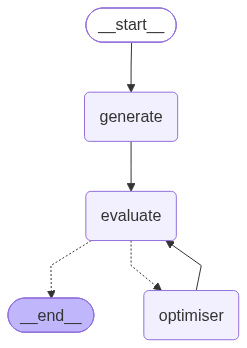

In [137]:
graph.add_node("generate",generate)
graph.add_node("evaluate",evaluate)
graph.add_node("optimiser",optimiser)

graph.add_edge(START,"generate")
graph.add_edge("generate","evaluate")
graph.add_conditional_edges('evaluate',get_conditional_edge)

graph.add_edge("optimiser","evaluate")

graph.compile()

In [ ]:
workflow=graph.compile()
initial_state={
    'topic':'indian wife sex position',
    'iteration':1,
    'max_iteration':5
}
final_state=workflow.invoke(initial_state)
final_state

{'topic': 'indian wife sex position',
 'tweet': 'She said “tikka twist” – I pictured a curry. Turns out the only thing that got turned over was the bed. #spice #romance',
 'evaluation': 'approved',
 'feedback': 'The tweet lands with a clever wordplay that turns a culinary phrase into a bedroom mishap, keeping it concise and punchy while the hashtags add a playful twist. Its humor is subtle yet effective, likely to catch the eye of those who appreciate a quick, witty surprise. While the joke is fresh enough to avoid the feeling of a tired meme, its relatability could be limited to a niche audience that enjoys food‑puns. Overall, it’s a solid, scroll‑stopping tweet that balances originality, humor, and brevity well.',
 'iteration': 2,
 'max_iteration': 5,
 'tweet_history': ['She says, “let’s try the tikka twist,” I think of a curry, not a list.  \nIn our bedroom kitchen we stir love—no cookbook needed—just a spicy groove, nice. #spice #romance',
  'She said “tikka twist” – I pictured a c

In [ ]:
from rich.console import Console
from rich.markdown import Markdown

console=Console()

console.print(Markdown(final_state['tweet']))

New study: the “spicy spin” — sit, twist, serve curry, then watch the sauce do a salsa. The only thing hotter than 
the food is the dance. No heat‑map needed. #CoupleGoals #SpiceUpYourLife 🍛💃🔥

In [148]:
for tweet in final_state['tweet_history']:
    print(tweet)

She says, “let’s try the tikka twist,” I think of a curry, not a list.  
In our bedroom kitchen we stir love—no cookbook needed—just a spicy groove, nice. #spice #romance
She said “tikka twist” – I pictured a curry. Turns out the only thing that got turned over was the bed. #spice #romance


In [149]:
for tweet in final_state['feedback_history']:
    print(tweet)

The tweet has a whimsical, almost poetic vibe that hints at originality, but it falls short on punchiness and clear humor. The line break and long, lyrical phrasing dilute the scroll‑stopper impact, and the joke isn’t sharp enough to spark a viral moment. Tightening the wording, adding a more direct punch or twist, and trimming excess adjectives would sharpen the humor, make it more memorable, and increase retweet potential. The hashtag use is fine, but the overall structure feels more like a romantic lyric than a punchy, shareable tweet.
The tweet lands with a clever wordplay that turns a culinary phrase into a bedroom mishap, keeping it concise and punchy while the hashtags add a playful twist. Its humor is subtle yet effective, likely to catch the eye of those who appreciate a quick, witty surprise. While the joke is fresh enough to avoid the feeling of a tired meme, its relatability could be limited to a niche audience that enjoys food‑puns. Overall, it’s a solid, scroll‑stopping t